# NHANES 2021-2023 cardiovascular risk extract

Pulls 10 NHANES `.xpt` files, merges them on `SEQN`, derives non-HDL cholesterol and CKD-EPI 2021 eGFR, and writes a parquet file.

In [1]:
import pandas as pd, numpy as np
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

BASE = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/{}.xpt"
FILES = ["DEMO_L", "TCHOL_L", "HDL_L", "GHB_L", "BIOPRO_L",
         "BPXO_L", "BMX_L", "SMQ_L", "BPQ_L", "DIQ_L"]

CACHE = Path("xpt_cache")
CACHE.mkdir(exist_ok=True)

## Download and merge

`BPXO_L` carries a byte column (`BPAOARM`), so the zero fix-up is restricted to numeric columns. Four of the lab files repeat `WTPH2YR`, which would otherwise collide during the merge.

In [2]:
def load(name):
    path = CACHE / f"{name}.xpt"
    if not path.exists():
        urlretrieve(BASE.format(name), path)
    df = pd.read_sas(path, format="xport")
    num = df.select_dtypes("number").columns
    df[num] = df[num].mask(df[num].abs() < 1e-70, 0)   # SAS-transport zero quirk
    return df


dfs = {f: load(f) for f in FILES}
df = dfs["DEMO_L"]
for f in FILES[1:]:
    right = dfs[f]
    dupes = right.columns.intersection(df.columns).drop("SEQN")
    df = df.merge(right.drop(columns=dupes), on="SEQN", how="left")

for f in FILES:
    print(f"{f:9s} {dfs[f].shape}")
print(f"\nmerged    {df.shape}")

DEMO_L    (11933, 27)
TCHOL_L   (8068, 4)
HDL_L     (8068, 4)
GHB_L     (7199, 3)
BIOPRO_L  (7199, 42)
BPXO_L    (7801, 12)
BMX_L     (8860, 22)
SMQ_L     (9015, 9)
BPQ_L     (8501, 6)
DIQ_L     (11744, 9)

merged    (11933, 126)


## Derive the analytic table

In [3]:
def ckd_epi_2021(scr, age, female):               # race-free eGFR
    k, a = np.where(female, 0.7, 0.9), np.where(female, -0.241, -0.302)
    r = scr / k
    return 142 * np.minimum(r, 1)**a * np.maximum(r, 1)**-1.200 * 0.9938**age * np.where(female, 1.012, 1)


out = pd.DataFrame({
    "seqn": df.SEQN,
    "age": df.RIDAGEYR,
    "sex": df.RIAGENDR.map({1: "male", 2: "female"}),
    "tc_mgdl": df.LBXTC,
    "hdl_mgdl": df.LBDHDD,
    "hba1c": df.LBXGH,
    "creatinine": df.LBXSCR,
    "sbp": df[["BPXOSY1", "BPXOSY2", "BPXOSY3"]].mean(axis=1),
    "bmi": df.BMXBMI,
    "smoker": df.SMQ040.isin([1, 2]),            # only asked if SMQ020 == 1
    "bp_meds": df.BPQ150 == 1,
    "lipid_meds": df.BPQ101D == 1,
    "diabetes": (df.DIQ010 == 1) | (df.LBXGH >= 6.5),
    "weight": df.WTMEC2YR,
})
out["non_hdl"] = out.tc_mgdl - out.hdl_mgdl
out["egfr"] = ckd_epi_2021(out.creatinine, out.age, out.sex == "female")
out = out[out.age.between(30, 79)].dropna(subset=["tc_mgdl", "hdl_mgdl", "sbp", "egfr"])
out.to_parquet("nhanes_2021_2023_cvd.parquet")

print(f"analytic sample: {out.shape[0]} rows x {out.shape[1]} columns")

analytic sample: 4460 rows x 16 columns


## Table preview

In [4]:
out.head(20)

,seqn,age,sex,tc_mgdl,hdl_mgdl,hba1c,creatinine,sbp,bmi,smoker,bp_meds,lipid_meds,diabetes,weight,non_hdl,egfr
0,130378.0,43.0,male,264.0,45.0,5.6,0.80,132.666667,27.0,False,True,False,False,54374.463898,219.0,112.614180
1,130379.0,66.0,male,214.0,60.0,5.6,0.79,117.000000,33.5,False,True,False,False,34084.721548,154.0,97.975999
2,130380.0,44.0,female,187.0,49.0,6.2,0.64,109.000000,29.7,False,False,True,True,81196.277992,138.0,111.687296
8,130386.0,34.0,male,183.0,46.0,5.1,0.82,115.000000,30.2,False,False,False,False,39988.452940,137.0,118.212538
9,130387.0,68.0,female,203.0,42.0,5.9,0.76,141.333333,42.6,False,True,False,False,20776.254850,161.0,85.298556
12,130390.0,31.0,female,159.0,39.0,5.9,0.80,111.333333,46.0,False,False,False,False,56314.156949,120.0,100.959522
13,130391.0,33.0,female,157.0,41.0,5.4,0.55,106.000000,38.9,True,False,False,False,60330.824308,116.0,124.044304
14,130392.0,74.0,female,191.0,37.0,5.6,0.59,158.333333,43.0,False,True,False,False,29427.774710,154.0,94.512138
15,130393.0,39.0,male,179.0,54.0,5.3,0.99,136.000000,46.1,False,True,False,False,55085.707641,125.0,99.375157
16,130394.0,51.0,male,183.0,48.0,4.8,0.84,110.666667,24.4,False,False,False,False,51305.024430,135.0,105.581019


## Columns, types and missing values

In [5]:
pd.DataFrame({"dtype": out.dtypes, "non_null": out.notna().sum(), "missing": out.isna().sum()})

,dtype,non_null,missing
seqn,float64,4460,0
age,float64,4460,0
sex,str,4460,0
tc_mgdl,float64,4460,0
hdl_mgdl,float64,4460,0
hba1c,float64,4460,0
creatinine,float64,4460,0
sbp,float64,4460,0
bmi,float64,4429,31
smoker,bool,4460,0


## Summary statistics

In [6]:
out.describe().T

,count,mean,std,min,25%,50%,75%,max
seqn,4460.0,136356.982063,3440.334866,130378.000000,133336.750000,136413.500000,139314.250000,142309.000000
age,4460.0,55.979372,13.803332,30.000000,44.000000,59.000000,67.000000,79.000000
tc_mgdl,4460.0,191.126009,42.975517,62.000000,162.000000,189.000000,217.000000,438.000000
hdl_mgdl,4460.0,54.655830,15.089170,22.000000,44.000000,53.000000,63.000000,159.000000
hba1c,4460.0,5.837578,1.140262,3.600000,5.300000,5.600000,5.900000,17.100000
creatinine,4460.0,0.896706,0.419489,0.350000,0.720000,0.850000,1.000000,15.170000
sbp,4460.0,123.171562,17.535320,70.000000,111.333333,121.000000,132.666667,232.333333
bmi,4429.0,29.993001,7.038685,14.900000,25.000000,28.700000,33.700000,68.900000
weight,4460.0,38133.232727,27211.119805,4581.595095,19169.287795,30444.707019,46826.027476,227108.296958
non_hdl,4460.0,136.470179,41.478985,21.000000,108.000000,132.500000,161.000000,373.000000


In [7]:
out[["smoker", "bp_meds", "lipid_meds", "diabetes"]].mean().rename("share").to_frame()

,share
smoker,0.158072
bp_meds,0.334305
lipid_meds,0.306951
diabetes,0.178027


## Full table

In [8]:
with pd.option_context("display.max_rows", None):
    print(out.to_string())

           seqn   age     sex  tc_mgdl  hdl_mgdl  hba1c  creatinine         sbp   bmi  smoker  bp_meds  lipid_meds  diabetes         weight  non_hdl        egfr
0      130378.0  43.0    male    264.0      45.0    5.6        0.80  132.666667  27.0   False     True       False     False   54374.463898    219.0  112.614180
1      130379.0  66.0    male    214.0      60.0    5.6        0.79  117.000000  33.5   False     True       False     False   34084.721548    154.0   97.975999
2      130380.0  44.0  female    187.0      49.0    6.2        0.64  109.000000  29.7   False    False        True      True   81196.277992    138.0  111.687296
8      130386.0  34.0    male    183.0      46.0    5.1        0.82  115.000000  30.2   False    False       False     False   39988.452940    137.0  118.212538
9      130387.0  68.0  female    203.0      42.0    5.9        0.76  141.333333  42.6   False     True       False     False   20776.254850    161.0   85.298556
12     130390.0  31.0  female    1

## Confirm the parquet round-trips

In [9]:
reloaded = pd.read_parquet("nhanes_2021_2023_cvd.parquet")
print(reloaded.shape, reloaded.equals(out))

(4460, 16) True


# Demographic correlates

Every demographic variable in NHANES lives in the single `DEMO_L` file; the other nine files are clinical measurements and questionnaires. `SEQN` (respondent sequence number) is the universal join key.

`DEMO_L` carries more than the age and sex already used above: race/ethnicity, education, income-to-poverty ratio, marital status, birth country, plus the survey design variables (`SDMVSTRA`, `SDMVPSU`) and weights.

In [10]:
demo_extra = (
    dfs["DEMO_L"][["SEQN", "RIDRETH3", "DMDEDUC2", "INDFMPIR", "DMDMARTZ", "DMDBORN4"]]
    .rename(columns={"SEQN": "seqn", "RIDRETH3": "race", "DMDEDUC2": "educ",
                     "INDFMPIR": "pir", "DMDMARTZ": "marital", "DMDBORN4": "foreign_born"})
)

d = out.merge(demo_extra, on="seqn", how="left")
d["female"] = (d.sex == "female").astype(float)
d["educ"] = d.educ.where(d.educ <= 5)   # 7 = refused, 9 = don't know
d["pir"] = d.pir.where(d.pir <= 5)      # 5 = capped at 5x poverty line

RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "White", 4: "Black",
        6: "Asian", 7: "Other/Multi"}
d["race_label"] = d.race.map(RACE)

feats = ["sbp", "tc_mgdl", "hdl_mgdl", "non_hdl", "hba1c", "creatinine", "egfr", "bmi",
         "bp_meds", "lipid_meds", "diabetes", "smoker"]
demos = ["age", "female", "educ", "pir"]
print(d.shape)

(4460, 23)


## Pick the coefficient that matches the variable types

| demographic | type | against a continuous feature | against a binary feature |
|---|---|---|---|
| `age`, `pir` | continuous | Pearson (linear) or Spearman (monotone) | point-biserial = Pearson on 0/1 |
| `female` | binary | point-biserial | phi coefficient |
| `educ` | ordinal | Spearman | Spearman / rank test |
| `race` | nominal | group means or eta-squared | Cramer's V |

Pearson on a nominal code like `race` is meaningless, since the 1-7 integers have no order.

NHANES also oversamples some groups by design, so an unweighted correlation estimates the correlation in the *sample*, not the US population. The weighted version below uses `WTMEC2YR`.

In [11]:
def wcorr(x, y, w):
    """Survey-weighted Pearson correlation, pairwise-complete."""
    m = x.notna() & y.notna() & w.notna()
    x, y, w = x[m].astype(float), y[m].astype(float), w[m].astype(float)
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx) * (y - my), weights=w)
    vx = np.average((x - mx) ** 2, weights=w)
    vy = np.average((y - my) ** 2, weights=w)
    return cov / np.sqrt(vx * vy)


rows = {}
for f in feats:
    rows[f] = {(g, kind): (d[f].astype(float).corr(d[g].astype(float)) if kind == "unwt"
                           else wcorr(d[f], d[g], d.weight))
               for g in demos for kind in ("unwt", "wtd")}

corr_tab = pd.DataFrame(rows).T
corr_tab.columns = pd.MultiIndex.from_tuples(corr_tab.columns)
corr_tab.round(3)

age        female          educ           pir       
             unwt    wtd   unwt    wtd   unwt    wtd   unwt    wtd
sbp         0.317  0.330 -0.131 -0.160 -0.125 -0.133 -0.056 -0.058
tc_mgdl    -0.051 -0.035  0.135  0.073  0.066  0.044  0.049  0.048
hdl_mgdl    0.112  0.134  0.304  0.327  0.146  0.154  0.113  0.116
non_hdl    -0.093 -0.082  0.029 -0.041  0.016 -0.010  0.009  0.008
hba1c       0.189  0.187 -0.039 -0.037 -0.211 -0.204 -0.146 -0.145
creatinine  0.119  0.113 -0.285 -0.310 -0.011 -0.024 -0.016  0.001
egfr       -0.585 -0.591  0.025 -0.001  0.007  0.015 -0.011 -0.014
bmi        -0.026 -0.016  0.063  0.044 -0.074 -0.092 -0.076 -0.093
bp_meds     0.373  0.385 -0.029 -0.009 -0.122 -0.108 -0.086 -0.075
lipid_meds  0.418  0.420 -0.083 -0.067 -0.078 -0.073 -0.010 -0.011
diabetes    0.198  0.211 -0.047 -0.041 -0.181 -0.160 -0.133 -0.128
smoker     -0.058 -0.033 -0.078 -0.087 -0.240 -0.243 -0.259 -0.241

## Nonlinearity: Pearson vs Spearman

A big gap between the two means the relationship is monotone but not straight, so a single Pearson r understates it.

In [12]:
nl = pd.DataFrame({
    "pearson": [d.age.corr(d[f].astype(float)) for f in feats],
    "spearman": [d.age.corr(d[f].astype(float), method="spearman") for f in feats],
}, index=feats)
nl["gap"] = nl.spearman.abs() - nl.pearson.abs()
nl.sort_values("gap", ascending=False).round(3)

,pearson,spearman,gap
hba1c,0.189,0.335,0.145
creatinine,0.119,0.182,0.063
egfr,-0.585,-0.609,0.024
non_hdl,-0.093,-0.113,0.020
tc_mgdl,-0.051,-0.069,0.019
smoker,-0.058,-0.066,0.009
sbp,0.317,0.322,0.005
lipid_meds,0.418,0.416,-0.002
hdl_mgdl,0.112,0.110,-0.002
bp_meds,0.373,0.369,-0.004


In [13]:
band = pd.cut(d.age, [30, 40, 50, 60, 70, 80], right=False)
d.groupby(band, observed=True)[["sbp", "hdl_mgdl", "egfr", "hba1c", "bmi",
                                "bp_meds", "lipid_meds", "diabetes"]].mean().round(2)

,sbp,hdl_mgdl,egfr,hba1c,bmi,bp_meds,lipid_meds,diabetes
age,,,,,,,,
"[30, 40)",114.15,51.95,106.73,5.40,30.12,0.06,0.03,0.04
"[40, 50)",118.40,53.47,99.29,5.66,29.98,0.15,0.09,0.11
"[50, 60)",123.24,54.19,90.91,6.00,30.65,0.35,0.31,0.21
"[60, 70)",126.77,56.07,83.49,6.01,29.83,0.45,0.42,0.23
"[70, 80)",129.83,56.42,74.08,5.97,29.49,0.54,0.56,0.25


## Group means for the nominal and binary demographics

In [14]:
d.groupby("sex")[feats].mean().T.assign(diff=lambda x: x.female - x.male).round(3)

sex,female,male,diff
sbp,121.075,125.702,-4.627
tc_mgdl,196.399,184.763,11.636
hdl_mgdl,58.826,49.623,9.202
non_hdl,137.573,135.140,2.433
hba1c,5.797,5.886,-0.089
creatinine,0.788,1.028,-0.241
egfr,90.069,89.110,0.959
bmi,30.394,29.510,0.884
bp_meds,0.322,0.349,-0.027
lipid_meds,0.272,0.349,-0.077


In [15]:
d.groupby("race_label")[["sbp", "tc_mgdl", "hdl_mgdl", "hba1c", "egfr", "bmi",
                         "bp_meds", "lipid_meds", "diabetes"]].mean().round(2)

,sbp,tc_mgdl,hdl_mgdl,hba1c,egfr,bmi,bp_meds,lipid_meds,diabetes
race_label,,,,,,,,,
Asian,123.55,199.18,56.32,5.88,97.91,25.38,0.30,0.28,0.16
Black,127.90,180.71,55.18,6.07,83.84,31.63,0.48,0.31,0.25
Mexican American,122.00,190.21,50.30,6.15,100.27,31.07,0.25,0.21,0.26
Other Hispanic,121.73,192.11,52.36,5.90,95.41,29.56,0.32,0.30,0.18
Other/Multi,123.19,194.31,53.23,5.94,89.26,30.18,0.32,0.32,0.21
White,122.62,191.99,55.42,5.73,87.88,30.04,0.32,0.32,0.15


## Heatmap

Full feature-by-feature matrix, with the demographics included.

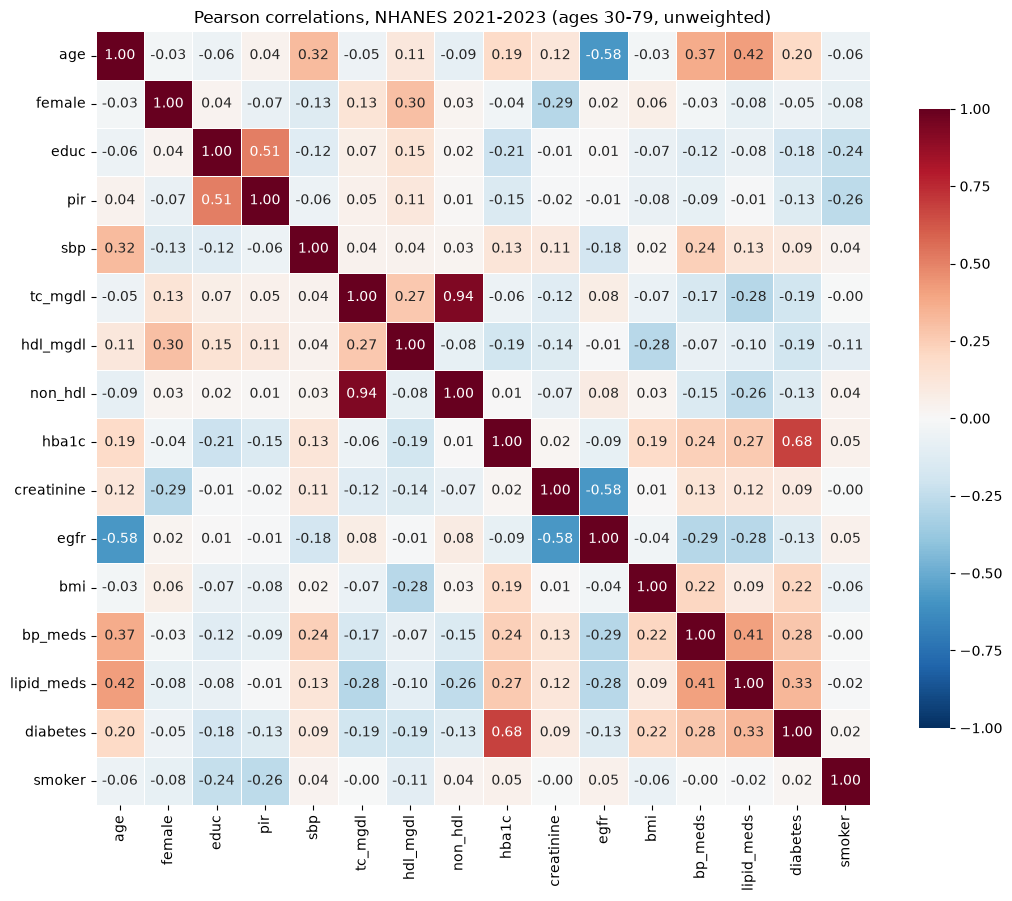

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

mat = d[demos + feats].astype(float).corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Pearson correlations, NHANES 2021-2023 (ages 30-79, unweighted)")
plt.tight_layout()
plt.savefig("demographic_correlations.png", dpi=120)
plt.show()

## Watch out for built-in correlations

Four pairs in this table are correlated by construction, not by biology. They will look like strong findings and leak badly if used together as model features.

In [17]:
checks = [
    ("egfr", "age", "age is a term in CKD-EPI (0.9938**age)"),
    ("egfr", "creatinine", "creatinine is the input to CKD-EPI"),
    ("non_hdl", "tc_mgdl", "non_hdl = tc_mgdl - hdl_mgdl"),
    ("diabetes", "hba1c", "hba1c >= 6.5 is part of the diabetes definition"),
]
pd.DataFrame(
    [{"pair": f"{a} ~ {b}", "r": round(d[a].astype(float).corr(d[b].astype(float)), 3),
      "why": why} for a, b, why in checks]
).set_index("pair")

,r,why
pair,,
egfr ~ age,-0.585,age is a term in CKD-EPI (0.9938**age)
egfr ~ creatinine,-0.583,creatinine is the input to CKD-EPI
non_hdl ~ tc_mgdl,0.937,non_hdl = tc_mgdl - hdl_mgdl
diabetes ~ hba1c,0.683,hba1c >= 6.5 is part of the diabetes definition


## Partial correlation

Age and sex confound nearly everything else, so the useful question is usually what remains after adjusting for them. Here age's association survives controlling for sex and BMI almost untouched.

In [18]:
def partial_corr(y, x, ctrl):
    """Correlation of y and x after linearly removing the ctrl columns from both."""
    m = d[[y, x] + ctrl].notna().all(axis=1)
    A = np.c_[np.ones(m.sum()), d.loc[m, ctrl].astype(float).to_numpy()]
    resid = lambda col: (col.to_numpy() - A @ np.linalg.lstsq(A, col, rcond=None)[0])
    return np.corrcoef(resid(d.loc[m, y].astype(float)),
                       resid(d.loc[m, x].astype(float)))[0, 1]


pd.DataFrame([
    {"feature": f,
     "r with age": round(d[f].corr(d.age), 3),
     "partial (sex, bmi)": round(partial_corr(f, "age", ["female", "bmi"]), 3)}
    for f in ["sbp", "hdl_mgdl", "hba1c", "tc_mgdl", "non_hdl"]
]).set_index("feature")

,r with age,"partial (sex, bmi)"
feature,,
sbp,0.317,0.318
hdl_mgdl,0.112,0.122
hba1c,0.189,0.199
tc_mgdl,-0.051,-0.049
non_hdl,-0.093,-0.090
